In [8]:
import requests
import pandas as pd
import io
import matplotlib.pyplot as plt
import numpy as np

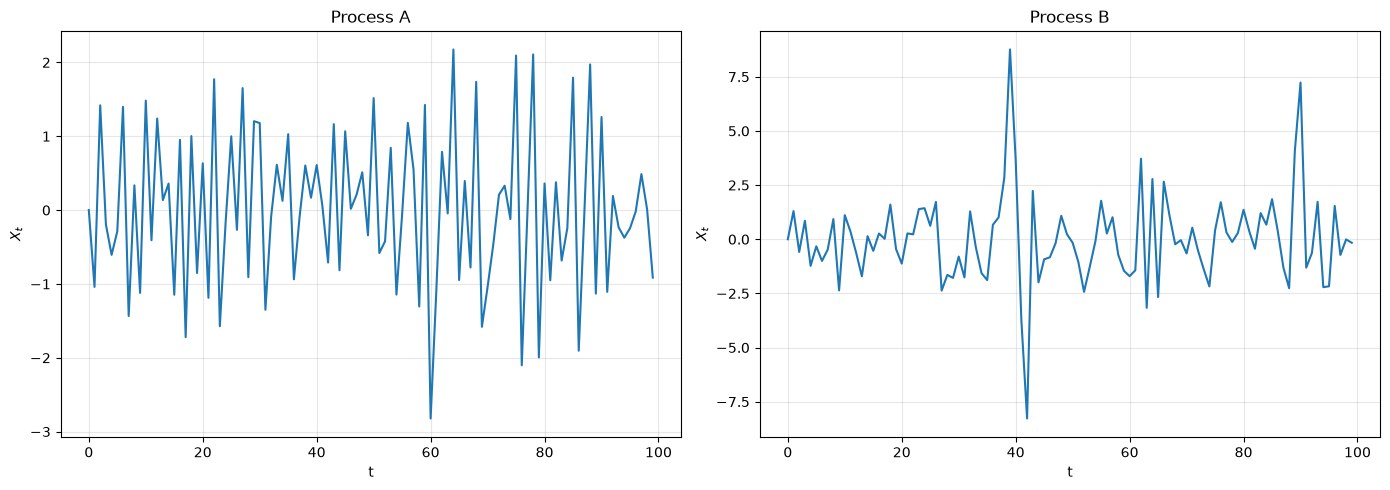

In [9]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

N = 100

# Noise terms
e_A = rng.normal(0, 1, N)
e_B = rng.normal(0, 1, N)

# Storage
X_A = np.zeros(N)
X_B = np.zeros(N)

# Initial values
X_A[0] = 0
X_B[0] = 0


# Process A
for t in range(1, N):

    if X_A[t - 1] >= 0:
        X_A[t] = -0.8 * X_A[t - 1] + e_A[t]

    else:
        X_A[t] = 0.8 * X_A[t - 1] + 1.5 + e_A[t]


# Process B
for t in range(1, N):

    X_B[t] = np.sqrt(
        1 + X_B[t - 1]**2
    ) * e_B[t]


# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(X_A)
axes[0].set_title("Process A")
axes[0].set_xlabel("t")
axes[0].set_ylabel(r"$X_t$")
axes[0].grid(alpha=0.3)

axes[1].plot(X_B)
axes[1].set_title("Process B")
axes[1].set_xlabel("t")
axes[1].set_ylabel(r"$X_t$")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
def k(u):
    """
    Box kernel:

    k(u) = 1 if |u| <= 1
           0 otherwise
    """
    return 1 if abs(u) <= 1 else 0


def M_hat(x, X, h):
    """
    Estimate

        M(x) = E[X_t | X_{t-1} = x]

    For d = 1 and i_1 = 1:

                  sum X_s * k((x - X_{s-1}) / h)
    M_hat(x) = -------------------------------------
                       sum k((x - X_{s-1}) / h)
    """

    numerator = sum(
        X[s] * k((x - X[s - 1]) / h)
        for s in range(1, len(X))
    )

    denominator = sum(
        k((x - X[s - 1]) / h)
        for s in range(1, len(X))
    )

    if denominator == 0:
        return np.nan

    return numerator / denominator

def V_hat(x, X, h):
    """
    Estimate

        V(x) = Var[X_t | X_{t-1} = x]
    """

    mean = M_hat(x, X, h)

    if np.isnan(mean):
        return np.nan

    numerator = sum(
        (X[s] - mean)**2 * k((x - X[s - 1]) / h)
        for s in range(1, len(X))
    )

    denominator = sum(
        k((x - X[s - 1]) / h)
        for s in range(1, len(X))
    )

    if denominator == 0:
        return np.nan

    return numerator / denominator

In [11]:
h = 0.5
x = 1.0

print("Process A")
print("Conditional mean:", M_hat(x, X_A, h))
print("Conditional variance:", V_hat(x, X_A, h))

print()

print("Process B")
print("Conditional mean:", M_hat(x, X_B, h))
print("Conditional variance:", V_hat(x, X_B, h))

Process A
Conditional mean: -0.5955866572964755
Conditional variance: 0.7265248045743932

Process B
Conditional mean: 0.3006382271771989
Conditional variance: 1.5006962127236252


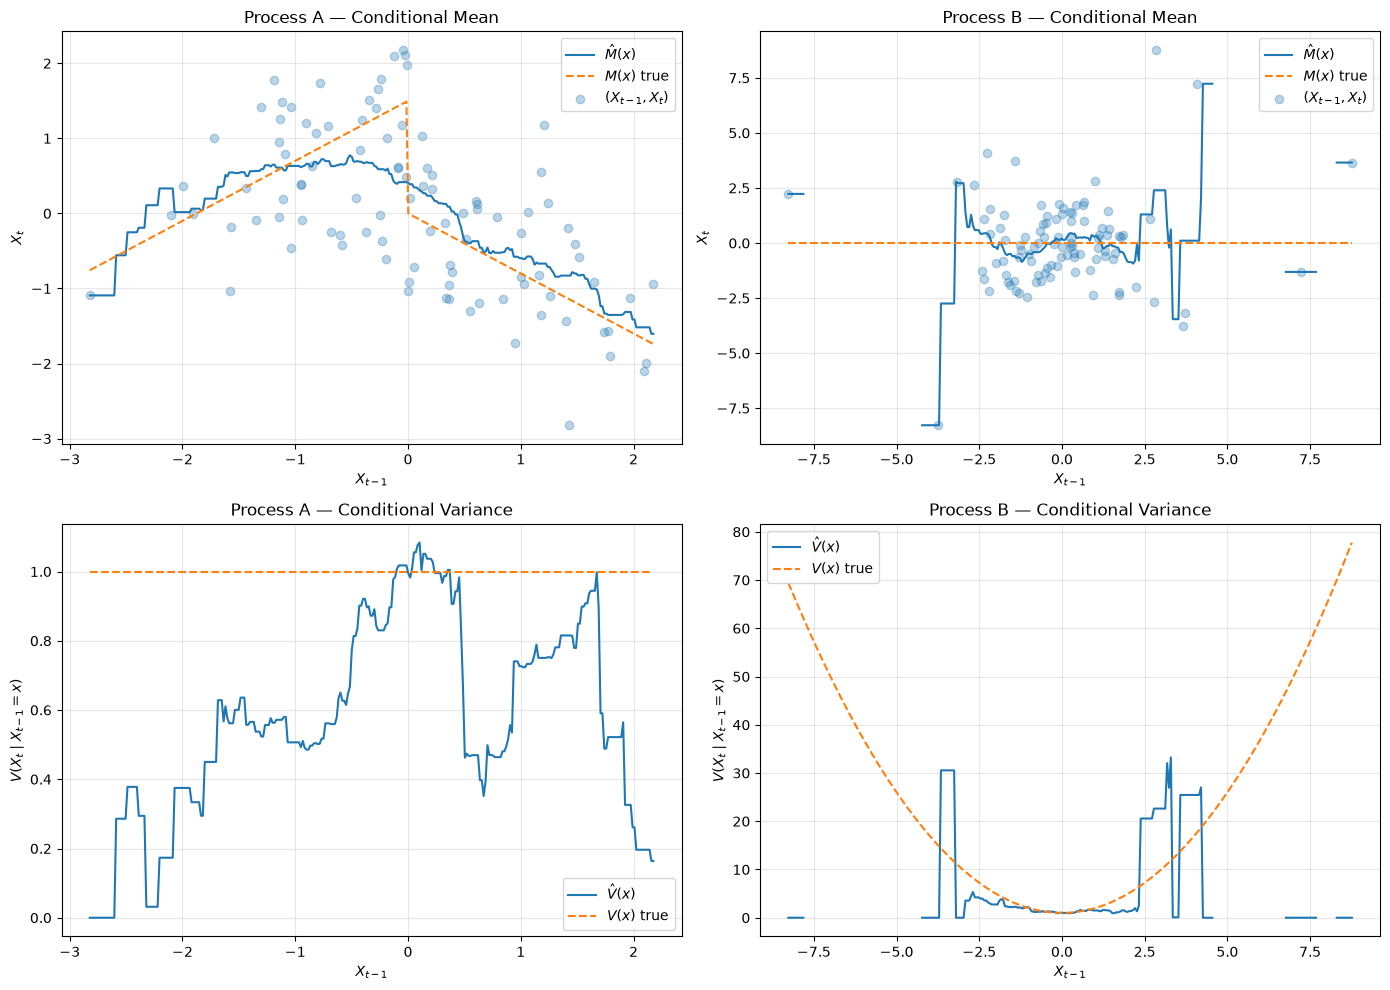

In [ ]:
# Bandwidth
h = 0.6

fig, axes = plt.subplots(2, 2, figsize=(14, 10))


# ==================================================
# Process A
# ==================================================

x_A = np.linspace(X_A.min(), X_A.max(), 300)

# Kernel estimates
M_A_est = np.array([
    M_hat(x, X_A, h)
    for x in x_A
])

V_A_est = np.array([
    V_hat(x, X_A, h)
    for x in x_A
])

# True conditional mean
M_A_true = np.where(
    x_A >= 0,
    -0.8 * x_A,
    0.8 * x_A + 1.5
)

# True conditional variance
V_A_true = np.ones_like(x_A)


# Conditional mean
axes[0, 0].plot(
    x_A,
    M_A_est,
    label=r"$\hat{M}(x)$"
)

axes[0, 0].plot(
    x_A,
    M_A_true,
    linestyle="--",
    label=r"$M(x)$ true"
)

axes[0, 0].scatter(
    X_A[:-1],
    X_A[1:],
    alpha=0.3,
    label=r"$(X_{t-1},X_t)$"
)

axes[0, 0].set_title("Process A — Conditional Mean")
axes[0, 0].set_xlabel(r"$X_{t-1}$")
axes[0, 0].set_ylabel(r"$X_t$")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)


# Conditional variance
axes[1, 0].plot(
    x_A,
    V_A_est,
    label=r"$\hat{V}(x)$"
)

axes[1, 0].plot(
    x_A,
    V_A_true,
    linestyle="--",
    label=r"$V(x)$ true"
)

axes[1, 0].set_title("Process A — Conditional Variance")
axes[1, 0].set_xlabel(r"$X_{t-1}$")
axes[1, 0].set_ylabel(r"$V(X_t \mid X_{t-1}=x)$")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)


# ==================================================
# Process B
# ==================================================

x_B = np.linspace(X_B.min(), X_B.max(), 300)

# Kernel estimates
M_B_est = np.array([
    M_hat(x, X_B, h)
    for x in x_B
])

V_B_est = np.array([
    V_hat(x, X_B, h)
    for x in x_B
])

# True conditional mean
M_B_true = np.zeros_like(x_B)

# True conditional variance
V_B_true = 1 + x_B**2


# Conditional mean
axes[0, 1].plot(
    x_B,
    M_B_est,
    label=r"$\hat{M}(x)$"
)

axes[0, 1].plot(
    x_B,
    M_B_true,
    linestyle="--",
    label=r"$M(x)$ true"
)

axes[0, 1].scatter(
    X_B[:-1],
    X_B[1:],
    alpha=0.3,
    label=r"$(X_{t-1},X_t)$"
)

axes[0, 1].set_title("Process B — Conditional Mean")
axes[0, 1].set_xlabel(r"$X_{t-1}$")
axes[0, 1].set_ylabel(r"$X_t$")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)


# Conditional variance
axes[1, 1].plot(
    x_B,
    V_B_est,
    label=r"$\hat{V}(x)$"
)

axes[1, 1].plot(
    x_B,
    V_B_true,
    linestyle="--",
    label=r"$V(x)$ true"
)

axes[1, 1].set_title("Process B — Conditional Variance")
axes[1, 1].set_xlabel(r"$X_{t-1}$")
axes[1, 1].set_ylabel(r"$V(X_t \mid X_{t-1}=x)$")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)


plt.tight_layout()
plt.show()

# Simulation

In [13]:
# ==================================================
# Kernel
# ==================================================

def k(u):
    """
    Gaussian kernel:

    k(u) = 1/sqrt(2*pi) * exp(-u^2 / 2)
    """
    return (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * u**2)


# ==================================================
# Simulate processes
# ==================================================

def simulate_process_A(N, rng):
    X = np.zeros(N)
    e = rng.normal(0, 1, N)

    for t in range(1, N):
        if X[t - 1] >= 0:
            X[t] = -0.8 * X[t - 1] + e[t]
        else:
            X[t] = 0.8 * X[t - 1] + 1.5 + e[t]

    return X


def simulate_process_B(N, rng):
    X = np.zeros(N)
    e = rng.normal(0, 1, N)

    for t in range(1, N):
        X[t] = np.sqrt(1 + X[t - 1]**2) * e[t]

    return X


# ==================================================
# Kernel estimators
# ==================================================

def M_hat(x, X, h):
    """
    Estimate

        M(x) = E[X_t | X_{t-1} = x]
    """

    weights = np.array([
        k((x - X[s - 1]) / h)
        for s in range(1, len(X))
    ])

    numerator = sum(
        weights[s - 1] * X[s]
        for s in range(1, len(X))
    )

    denominator = sum(weights)

    if denominator == 0:
        return np.nan

    return numerator / denominator


def V_hat(x, X, h):
    """
    Estimate

        V(x) = Var[X_t | X_{t-1} = x]
    """

    mean = M_hat(x, X, h)

    weights = np.array([
        k((x - X[s - 1]) / h)
        for s in range(1, len(X))
    ])

    numerator = sum(
        weights[s - 1] * (X[s] - mean)**2
        for s in range(1, len(X))
    )

    denominator = sum(weights)

    if denominator == 0:
        return np.nan

    return numerator / denominator


# ==================================================
# Experiment
# ==================================================

N = 100
h = 0.6
n_experiments = 10

rng = np.random.default_rng(42)

results = []

for experiment in range(n_experiments):

    X_A = simulate_process_A(N, rng)
    X_B = simulate_process_B(N, rng)

    # Common grids
    x_A = np.linspace(X_A.min(), X_A.max(), 300)
    x_B = np.linspace(X_B.min(), X_B.max(), 300)

    # Estimated conditional means
    M_A_est = np.array([
        M_hat(x, X_A, h)
        for x in x_A
    ])

    M_B_est = np.array([
        M_hat(x, X_B, h)
        for x in x_B
    ])

    # Estimated conditional variances
    V_A_est = np.array([
        V_hat(x, X_A, h)
        for x in x_A
    ])

    V_B_est = np.array([
        V_hat(x, X_B, h)
        for x in x_B
    ])

    results.append({
        "X_A": X_A,
        "X_B": X_B,
        "x_A": x_A,
        "x_B": x_B,
        "M_A": M_A_est,
        "M_B": M_B_est,
        "V_A": V_A_est,
        "V_B": V_B_est,
    })

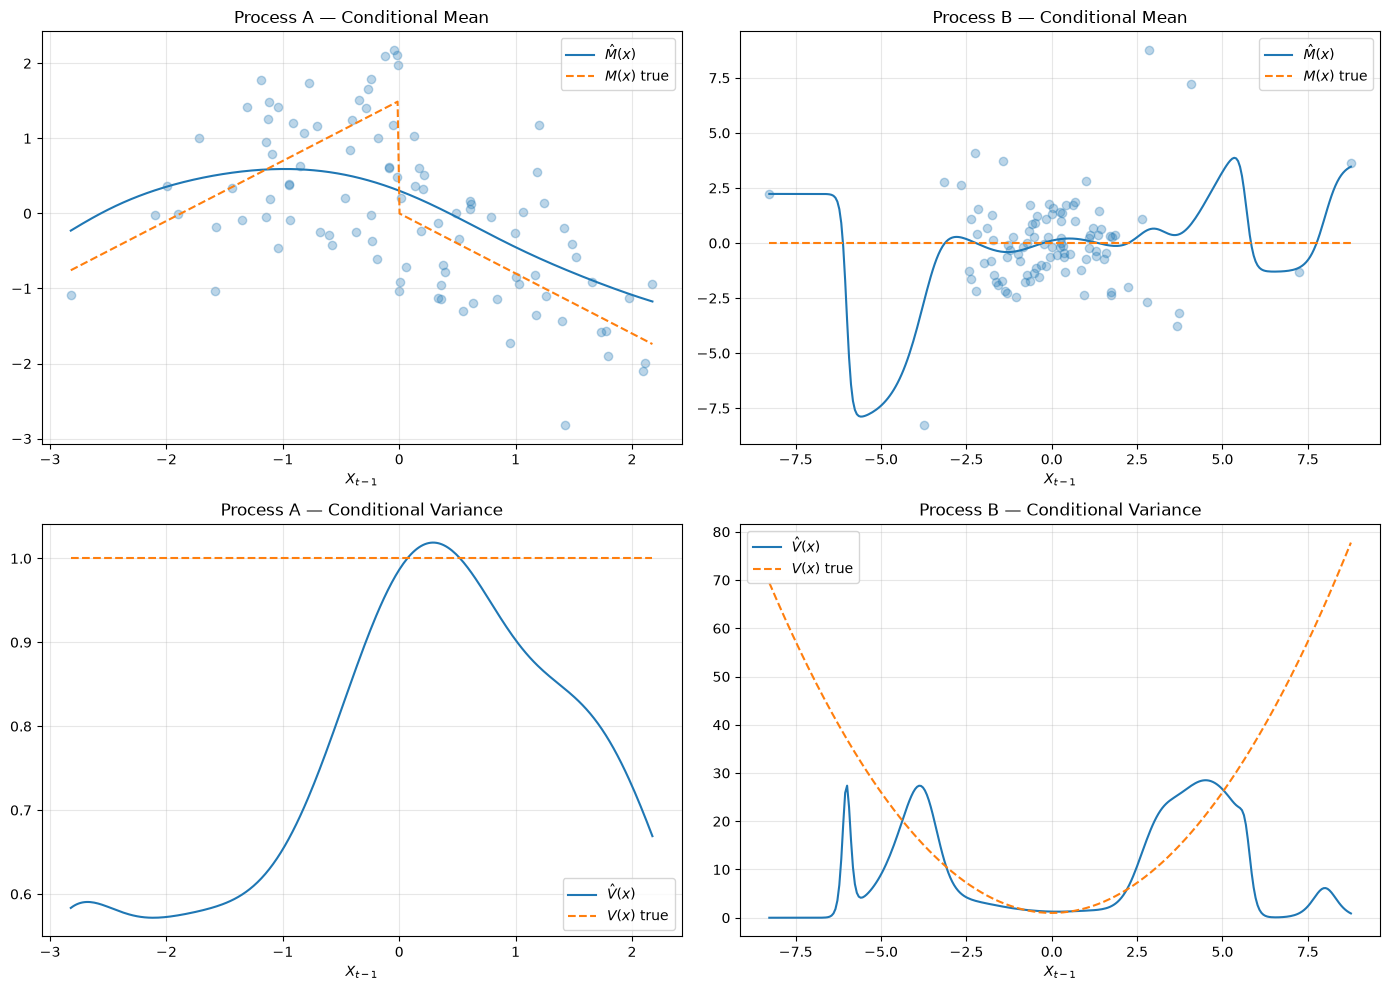

In [14]:
r = results[0]

x_A = r["x_A"]
x_B = r["x_B"]

M_A_true = np.where(
    x_A >= 0,
    -0.8 * x_A,
    0.8 * x_A + 1.5
)

V_A_true = np.ones_like(x_A)

M_B_true = np.zeros_like(x_B)
V_B_true = 1 + x_B**2


fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Process A mean
axes[0, 0].plot(x_A, r["M_A"], label=r"$\hat{M}(x)$")
axes[0, 0].plot(x_A, M_A_true, "--", label=r"$M(x)$ true")
axes[0, 0].scatter(
    r["X_A"][:-1],
    r["X_A"][1:],
    alpha=0.3
)
axes[0, 0].set_title("Process A — Conditional Mean")
axes[0, 0].legend()

# Process B mean
axes[0, 1].plot(x_B, r["M_B"], label=r"$\hat{M}(x)$")
axes[0, 1].plot(x_B, M_B_true, "--", label=r"$M(x)$ true")
axes[0, 1].scatter(
    r["X_B"][:-1],
    r["X_B"][1:],
    alpha=0.3
)
axes[0, 1].set_title("Process B — Conditional Mean")
axes[0, 1].legend()

# Process A variance
axes[1, 0].plot(x_A, r["V_A"], label=r"$\hat{V}(x)$")
axes[1, 0].plot(x_A, V_A_true, "--", label=r"$V(x)$ true")
axes[1, 0].set_title("Process A — Conditional Variance")
axes[1, 0].legend()

# Process B variance
axes[1, 1].plot(x_B, r["V_B"], label=r"$\hat{V}(x)$")
axes[1, 1].plot(x_B, V_B_true, "--", label=r"$V(x)$ true")
axes[1, 1].set_title("Process B — Conditional Variance")
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.set_xlabel(r"$X_{t-1}$")

plt.tight_layout()
plt.show()

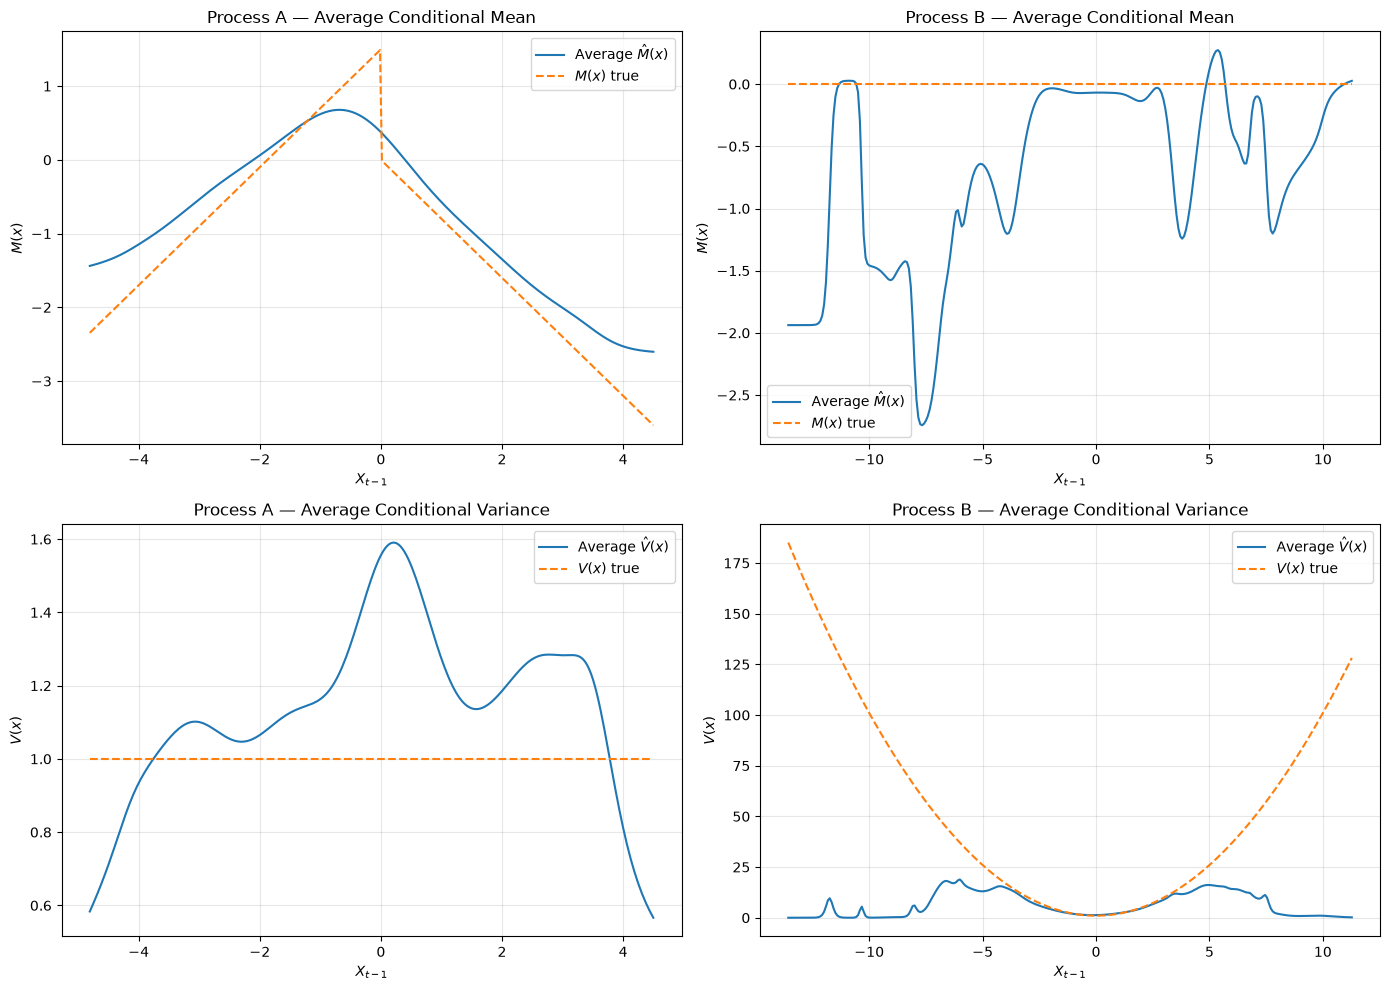

In [ ]:
# ==================================================
# Average over all experiments
# ==================================================

# Common x-grids across all experiments
x_A = np.linspace(
    min(r["X_A"].min() for r in results),
    max(r["X_A"].max() for r in results),
    300
)

x_B = np.linspace(
    min(r["X_B"].min() for r in results),
    max(r["X_B"].max() for r in results),
    300
)


# Recalculate estimates on the same x-grid for every experiment
M_A_all = np.array([
    [M_hat(x, r["X_A"], h) for x in x_A]
    for r in results
])

V_A_all = np.array([
    [V_hat(x, r["X_A"], h) for x in x_A]
    for r in results
])

M_B_all = np.array([
    [M_hat(x, r["X_B"], h) for x in x_B]
    for r in results
])

V_B_all = np.array([
    [V_hat(x, r["X_B"], h) for x in x_B]
    for r in results
])


# Average across experiments
M_A_mean = np.nanmean(M_A_all, axis=0)
V_A_mean = np.nanmean(V_A_all, axis=0)

M_B_mean = np.nanmean(M_B_all, axis=0)
V_B_mean = np.nanmean(V_B_all, axis=0)


# ==================================================
# True functions
# ==================================================

M_A_true = np.where(
    x_A >= 0,
    -0.8 * x_A,
    0.8 * x_A + 1.5
)

V_A_true = np.ones_like(x_A)

M_B_true = np.zeros_like(x_B)
V_B_true = 1 + x_B**2


# ==================================================
# Plot
# ==================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))


# Process A - Conditional Mean
axes[0, 0].plot(
    x_A,
    M_A_mean,
    label=r"Average $\hat{M}(x)$"
)

axes[0, 0].plot(
    x_A,
    M_A_true,
    "--",
    label=r"$M(x)$ true"
)

axes[0, 0].set_title("Process A — Average Conditional Mean")
axes[0, 0].legend()


# Process B - Conditional Mean
axes[0, 1].plot(
    x_B,
    M_B_mean,
    label=r"Average $\hat{M}(x)$"
)

axes[0, 1].plome a t(
    x_B,
    M_B_true,
    "--",
    label=r"$M(x)$ true"
)

axes[0, 1].set_title("Process B — Average Conditional Mean")
axes[0, 1].legend()


# Process A - Conditional Variance
axes[1, 0].plot(
    x_A,
    V_A_mean,
    label=r"Average $\hat{V}(x)$"
)

axes[1, 0].plot(
    x_A,
    V_A_true,
    "--",
    label=r"$V(x)$ true"
)

axes[1, 0].set_title("Process A — Average Conditional Variance")
axes[1, 0].legend()


# Process B - Conditional Variance
axes[1, 1].plot(
    x_B,
    V_B_mean,
    label=r"Average $\hat{V}(x)$"
)

axes[1, 1].plot(
    x_B,
    V_B_true,
    "--",
    label=r"$V(x)$ true"
)

axes[1, 1].set_title("Process B — Average Conditional Variance")
axes[1, 1].legend()


for ax in axes.flat:
    ax.set_xlabel(r"$X_{t-1}$")
    ax.grid(alpha=0.3)

axes[0, 0].set_ylabel(r"$M(x)$")
axes[0, 1].set_ylabel(r"$M(x)$")
axes[1, 0].set_ylabel(r"$V(x)$")
axes[1, 1].set_ylabel(r"$V(x)$")

plt.tight_layout()
plt.show()

(-6.0, 4.0)

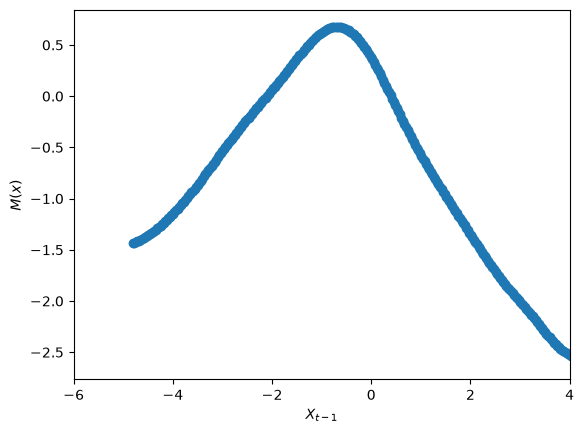

In [17]:
# Plot estimated x vs x
plt.scatter(x_A, M_A_mean, label=r"Estimated $\hat{M}(x)$")
plt.xlabel(r"$X_{t-1}$")
plt.ylabel(r"$M(x)$")
plt.xlim(-6, 4)